In [1]:
   import pandas as pd

   rides = pd.read_csv("../data/bikeshare-ridership-2024.csv", nrows=5)
   print(rides.columns.tolist())
   rides

['Trip_Id', 'Trip_Duration', 'Start_Station_Id', 'Start_Time', 'Start_Station_Name', 'End_Station_Id', 'End_Time', 'End_Station_Name', 'Bike_Id', 'User_Type', 'Bike_Model']


,Trip_Id,Trip_Duration,Start_Station_Id,Start_Time,Start_Station_Name,End_Station_Id,End_Time,End_Station_Name,Bike_Id,User_Type,Bike_Model
0,26682740,528,7041,2024-01-01 00:00:08,Edward St / Yonge St,7130.0,2024-01-01 00:08:56,Davenport Rd / Bedford Rd,7855,Casual,EFIT G5
1,26682742,1924,7245,2024-01-01 00:02:04,Tecumseth St / Queen St W - SMART,7259.0,2024-01-01 00:34:08,Lower Spadina Ave / Lake Shore Blvd W,2453,Casual,ICONIC
2,26682743,2741,7052,2024-01-01 00:03:25,Wellington St W / Bay St,7366.0,2024-01-01 00:49:06,Fort York Blvd / Bathurst St - SMART,7332,Member,ICONIC
3,26682744,353,7041,2024-01-01 00:03:39,Edward St / Yonge St,7418.0,2024-01-01 00:09:32,College Park - Yonge St Entrance,782,Member,ICONIC
4,26682746,2118,7721,2024-01-01 00:04:44,Widmer St / King St W,7721.0,2024-01-01 00:40:02,Widmer St / King St W,1008,Member,ICONIC


In [2]:
import pandas as pd

# Read only the column we need (saves memory)
rides = pd.read_csv("../data/bikeshare-ridership-2024.csv",
                    usecols=["Start_Time"], parse_dates=["Start_Time"])

# Count rides per day
daily = (rides["Start_Time"].dt.normalize()
         .value_counts().sort_index()
         .rename_axis("date").reset_index(name="rides"))

# Load weather and merge
weather = pd.read_csv("../data/weather_2024.csv", parse_dates=["time"])
weather = weather.rename(columns={
    "time": "date",
    "temperature_2m_mean": "temp",
    "precipitation_sum": "rain",
    "snowfall_sum": "snow",
    "wind_speed_10m_max": "wind",
})
df = daily.merge(weather, on="date")

# Add calendar features
df["weekday"] = df["date"].dt.dayofweek
df["month"] = df["date"].dt.month
df["is_weekend"] = (df["weekday"] >= 5).astype(int)

df.to_csv("../data/daily_rides_weather.csv", index=False)
print(df.shape)
df.head()

(366, 9)


,date,rides,temp,rain,snow,wind,weekday,month,is_weekend
0,2024-01-01,3157,-1.5,0.7,0.49,14.5,0,1,0
1,2024-01-02,6623,-0.5,0.0,0.00,25.3,1,1,0
2,2024-01-03,7906,1.1,0.3,0.07,19.3,2,1,0
3,2024-01-04,7366,-3.7,0.0,0.00,23.5,3,1,0
4,2024-01-05,7419,-1.7,0.0,0.00,21.6,4,1,0


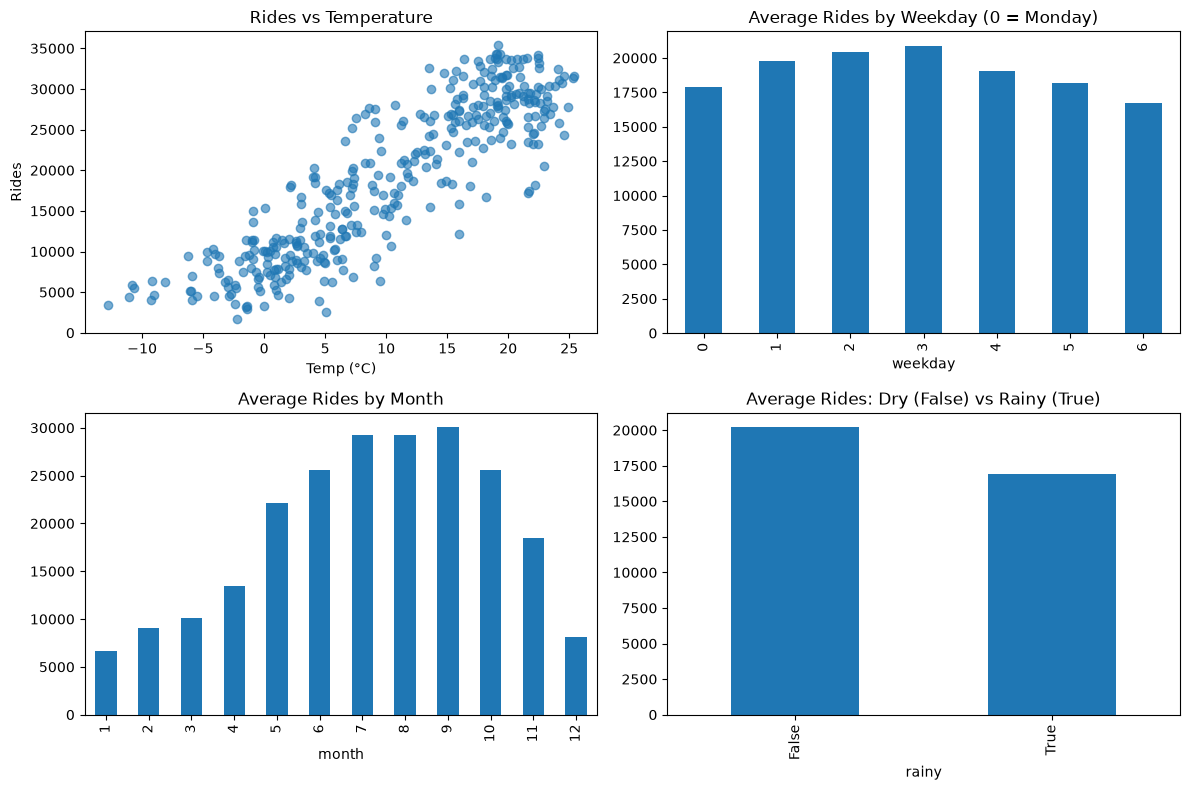

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 2, figsize=(12, 8))

# 1. Rides vs temperature
ax[0, 0].scatter(df["temp"], df["rides"], alpha=0.6)
ax[0, 0].set_title("Rides vs Temperature")
ax[0, 0].set_xlabel("Temp (°C)")
ax[0, 0].set_ylabel("Rides")

# 2. Average rides by weekday
df.groupby("weekday")["rides"].mean().plot(kind="bar", ax=ax[0, 1])
ax[0, 1].set_title("Average Rides by Weekday (0 = Monday)")

# 3. Average rides by month
df.groupby("month")["rides"].mean().plot(kind="bar", ax=ax[1, 0])
ax[1, 0].set_title("Average Rides by Month")

# 4. Rain vs no rain
df.assign(rainy=df["rain"] > 1).groupby("rainy")["rides"].mean().plot(kind="bar", ax=ax[1, 1])
ax[1, 1].set_title("Average Rides: Dry (False) vs Rainy (True)")

plt.tight_layout()
plt.savefig("../data/eda_charts.png", dpi=150)
plt.show()

## Key insights
- Ridership rises strongly with temperature, from about 5,000 rides/day below 0°C to over 30,000 above 20°C.
- Weekdays (especially Tue to Thu) are busier than weekends, which suggests commuting use.
- Demand peaks from July to September and drops sharply in winter.
- Rainy days average roughly 15% fewer rides than dry days.

In [ ]:
import os
import joblib
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

features = ["temp", "rain", "snow", "wind", "weekday", "month", "is_weekend"]
X = df[features]
y = df["rides"]

# Chronological split: train on earlier dates, test on the last 20%
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = (mean_absolute_error(y_test, pred), r2_score(y_test, pred))
    print(f"{name}: MAE = {results[name][0]:.0f} rides, R² = {results[name][1]:.2f}")

# Save the best model (lowest MAE)
best = min(results, key=lambda k: results[k][0])
os.makedirs("../models", exist_ok=True)
joblib.dump(models[best], "../models/best_model.joblib")
print("Saved:", best)

Linear Regression: MAE = 9341 rides, R² = -0.99
Random Forest: MAE = 7703 rides, R² = -0.64
Saved: Random Forest
